# K-Nearest Neighbors (KNN) on the Diabetes Dataset

**Problem statement:** Implement K-Nearest Neighbors on `diabetes.csv` and calculate the confusion matrix, accuracy, error rate, precision, and recall.

**Dataset:** [Kaggle — Diabetes Dataset](https://www.kaggle.com/datasets/abdallamahgoub/diabetes)

Place `diabetes.csv` in the same folder as this notebook. The target column in this dataset is `Outcome` (0 = non-diabetic, 1 = diabetic).

## 1. Install required libraries (if needed)
Skip this cell if the libraries are already installed.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, classification_report
)

## 3. Load and inspect the dataset

In [3]:
df = pd.read_csv("diabetes.csv")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset shape: (768, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


## 4. Clean the dataset

Remove duplicate rows and rows with missing values. In this commonly used dataset, zero values in some medical measurements can represent missing measurements, so replace zeros in those columns with their median.

In [4]:
df = df.drop_duplicates().dropna().copy()

zero_as_missing = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

for col in zero_as_missing:
    if col in df.columns:
        df[col] = df[col].replace(0, np.nan)
        df[col] = df[col].fillna(df[col].median())

print("Dataset shape after cleaning:", df.shape)
print("\nMissing values after cleaning:", df.isnull().sum().sum())
display(df.head())

Dataset shape after cleaning: (768, 9)

Missing values after cleaning: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 5. Separate features and target

In [5]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

Features shape: (768, 8)
Target shape: (768,)

Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


## 6. Split the data and standardize features

An 80:20 train-test split is used. The scaler is fitted only on the training data to avoid data leakage.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Training data: (614, 8)
Testing data: (154, 8)
Feature scaling completed.


## 7. Train the KNN classifier

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print("KNN model trained successfully.")

KNN model trained successfully.


## 8. Calculate the confusion matrix

Confusion Matrix:
[[83 17]
 [21 33]]


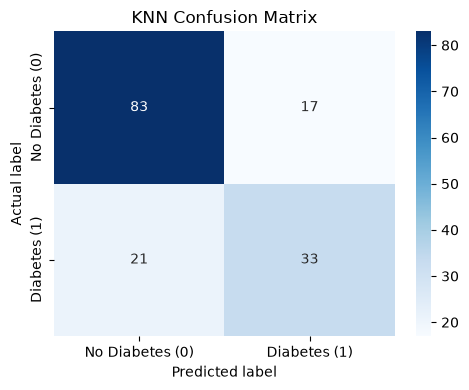

In [8]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Diabetes (0)", "Diabetes (1)"],
    yticklabels=["No Diabetes (0)", "Diabetes (1)"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Calculate evaluation metrics

Precision and recall are calculated for the positive class (`Outcome = 1`). Error rate is `1 - accuracy`.

In [9]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Accuracy :", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.7532
Error Rate: 0.2468
Precision: 0.66
Recall   : 0.6111

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



## Conclusion

The K-Nearest Neighbors classifier was trained on the diabetes dataset after cleaning and standardizing the features. Its performance was evaluated using the confusion matrix, accuracy, error rate, precision, and recall.

**Note:** Metric values depend on the dataset version, preprocessing, train-test split, and K value. This model is for educational use and is not a medical diagnostic tool.